# Notebook 07 — Stress Testing

VaR is calibrated to normal market conditions. By construction,
a 99% VaR model is expected to be breached on 1% of trading days —
it says nothing about how large those breaches will be, or how the
portfolio behaves when multiple risk factors move simultaneously in
the same direction.

Stress testing addresses this gap. Rather than estimating a
statistical loss threshold, it asks: what did this portfolio
actually lose during specific historical crises, and how does
that compare to what a VaR model, using only information available
at the time, would have predicted?

This notebook applies two forms of stress analysis. Historical
scenario analysis replays four crisis periods from within the
2015–2024 data window and measures realised portfolio losses.
Hypothetical shock analysis applies instantaneous percentage
shocks to the full portfolio value to bound potential losses
under severe but unobserved conditions.

The Basel III regulatory framework requires banks to complement
VaR-based capital models with stress testing precisely because
VaR is insufficient during tail events. The results here
contextualise the backtesting failures observed in Notebook 06.

### Choosing the Scenario Windows

The four crisis windows below weren't picked from a generic list —
they were found by locating the sharpest drawdowns in this portfolio's
own return series and matching each one to the market event it
corresponds to: the COVID-19 crash (Feb–Mar 2020), the Fed-driven
Q4 2018 selloff, the 2022 rate-hiking cycle, and the August 2015 China
devaluation/selloff. Start and end dates were adjusted by hand to
bracket each event's peak-to-trough window within the 2015–2024 sample.

### Benchmarking Against Pre-Crisis VaR

Comparing each crisis's worst-day loss against a single VaR figure
computed on the full 2015–2024 sample would be circular — that sample
already contains the crisis days themselves. Instead, each scenario is
benchmarked against its own VaR estimate, computed using only the 250
trading days immediately *before* that scenario began — the risk
figure a desk would actually have been holding on day one of the event.

## Outputs

- Historical scenario returns and worst-day losses
- Each scenario's own pre-crisis 99% VaR benchmark and the
  worst-day-loss / pre-crisis-VaR ratio
- A drawdown check verifying the chosen windows against the data
- Hypothetical shock analysis

Worst drawdown points in the sample (for reference):
Date
2020-03-23   -0.4915
2020-03-20   -0.4482
2020-03-18   -0.4093
2020-03-16   -0.3978
2020-03-19   -0.3965
2020-03-12   -0.3887
dtype: float64

Historical Stress Scenarios
----------------------------------------------------------------------------------
Scenario              Total Return   Worst Day  Pre-Crisis VaR99   Worst / VaR99
----------------------------------------------------------------------------------
COVID Crash                -37.86%     -11.74%           2.9826%            3.9x
2018 Selloff               -18.66%      -3.60%           3.0933%            1.2x
2022 Rate Shock              6.93%      -3.75%           2.4565%            1.5x
China Selloff               -9.13%      -4.09%           1.9879%            2.1x
----------------------------------------------------------------------------------

Worst / VaR99 = worst single-day loss in the scenario divided by
that scenario's OWN pre-crisis 99% VaR (estimated on

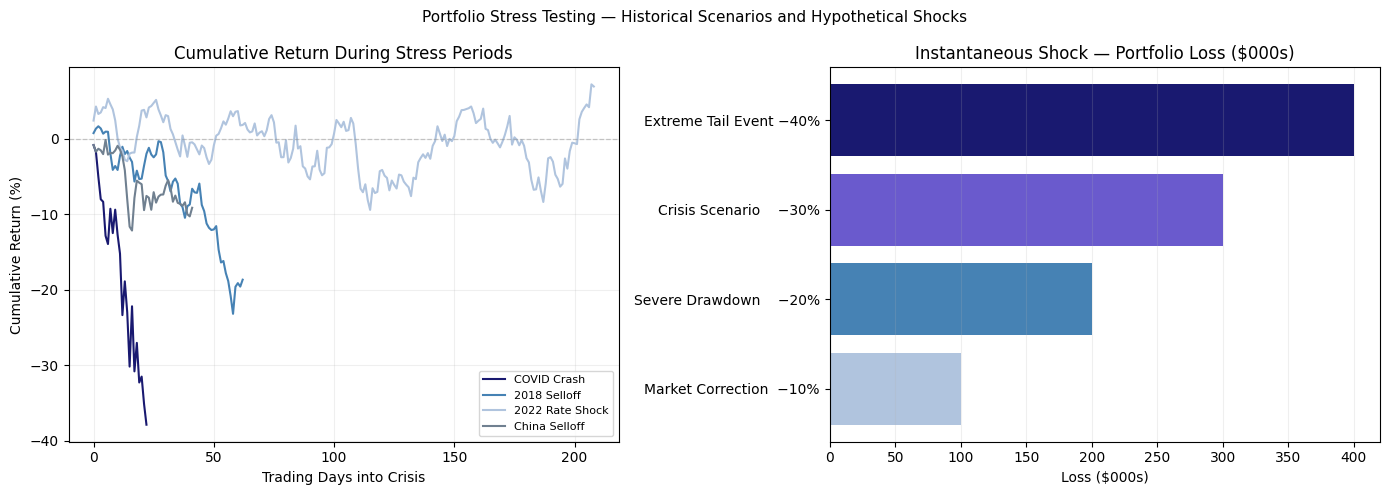

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.float_format', '{:.4f}'.format)

# Configuration 

weights = np.array([0.20, 0.20, 0.20, 0.20, 0.20])
portfolio_value = 1_000_000

# Load Data

log_returns = pd.read_csv('../data/log_returns.csv',index_col=0,parse_dates=True)
assert log_returns.isna().sum().sum() == 0

simple_returns = np.exp(log_returns) - 1
portfolio_simple_returns = simple_returns.dot(weights)
portfolio_returns = np.log1p(portfolio_simple_returns)


# Identifying Stress Periods

def worst_drawdown_windows(returns: pd.Series, n_windows: int = 6, window: int = 40) -> pd.Series:
    cum = returns.cumsum()
    rolling_peak = cum.rolling(window, min_periods=1).max()
    drawdown = cum - rolling_peak
    worst_points = drawdown.nsmallest(n_windows)
    return worst_points

print("Worst drawdown points in the sample (for reference):")
print(worst_drawdown_windows(portfolio_returns))


# Pre-Crisis VaR Benchmark
def pre_crisis_var(returns: pd.Series,
                    crisis_start: str,
                    confidence: float,
                    window: int = 250) -> float:
    cutoff = pd.Timestamp(crisis_start) - pd.Timedelta(days=1)
    history = returns.loc[:cutoff].tail(window)
    return -np.percentile(history, (1 - confidence) * 100)


# Historical Stress Scenarios


scenarios = {
    'COVID Crash':     ('2020-02-20', '2020-03-23'),
    '2018 Selloff':    ('2018-10-01', '2018-12-31'),
    '2022 Rate Shock': ('2022-01-01', '2022-10-31'),
    'China Selloff':   ('2015-08-01', '2015-09-30'),}

# Note: China Selloff (Aug 2015) has only ~150 trading days of
# pre-scenario history available in this dataset (data starts
# 2015-01-01), versus the full 250-day window used for the other
# three scenarios. Its pre-crisis VaR benchmark below is therefore
# estimated on a thinner sample and is less statistically reliable
# than the other three.

scenario_results = {}

for name, (start, end) in scenarios.items():
    period = portfolio_returns.loc[start:end]
    if len(period) < 10:
        continue
    pre_var_99 = pre_crisis_var(portfolio_returns, start, 0.99)
    scenario_results[name] = {
        'returns':     period,
        'total':       (np.exp(period.sum()) - 1) * 100,
        'worst_day':   period.min() * 100,
        'pre_var_99':  pre_var_99,}

print('\nHistorical Stress Scenarios')
print('-' * 82)
print(
    f"{'Scenario':<20}"
    f"{'Total Return':>14}"
    f"{'Worst Day':>12}"
    f"{'Pre-Crisis VaR99':>18}"
    f"{'Worst / VaR99':>16}")
print('-' * 82)

for name, data in scenario_results.items():
    worst_loss  = abs(data['worst_day']) / 100
    var_ratio   = worst_loss / data['pre_var_99']
    print(
        f"{name:<20}"
        f"{data['total']:>13.2f}%"
        f"{data['worst_day']:>11.2f}%"
        f"{data['pre_var_99']*100:>17.4f}%"
        f"{var_ratio:>15.1f}x")

print('-' * 82)
print("\nWorst / VaR99 = worst single-day loss in the scenario divided by")
print("that scenario's OWN pre-crisis 99% VaR (estimated only from data")
print("available before the scenario began). A ratio > 1 means the loss")
print("exceeded what the model, using only information available at the")
print("time, would have predicted on its worst day.")

covid_ratio = (abs(scenario_results['COVID Crash']['worst_day'] / 100)
    / scenario_results['COVID Crash']['pre_var_99'])
print( f"\nCOVID produced a ratio of {covid_ratio:.1f}x — the actual loss was")
print(f"{covid_ratio:.1f} times larger than the pre-crisis 99% VaR estimate.")
print("This is the quantitative argument for why stress testing complements")
print("VaR rather than replacing it: VaR is calibrated to typical days, not")
print("to the specific historical scenario about to unfold.")


# Hypothetical Shocks

shocks = {
    'Market Correction  −10%': -0.10,
    'Severe Drawdown    −20%': -0.20,
    'Crisis Scenario    −30%': -0.30,
    'Extreme Tail Event −40%': -0.40,}

shock_losses = {
    name: abs(pct) * portfolio_value
    for name, pct in shocks.items()}

print('\nHypothetical Shock Scenarios')
print('-' * 45)
print(f"{'Scenario':<28}{'Loss ($)':>15}")
print('-' * 45)
for name, loss in shock_losses.items():
    print(f"{name:<28}{loss:>14,.0f}")
print('-' * 45)


# Visualization

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(
    'Portfolio Stress Testing — Historical Scenarios and Hypothetical Shocks',fontsize=11)

ax1     = axes[0]
colors  = ['midnightblue', 'steelblue', 'lightsteelblue', 'slategray']

for (name, data), color in zip(scenario_results.items(), colors):
    cumulative = (np.exp(data['returns'].cumsum()) - 1) * 100
    ax1.plot(
        cumulative.values,
        linewidth=1.5,
        color=color,
        label=name)

ax1.axhline(0, color='gray', linestyle='--',
            linewidth=0.9, alpha=0.4)
ax1.set_title('Cumulative Return During Stress Periods')
ax1.set_xlabel('Trading Days into Crisis')
ax1.set_ylabel('Cumulative Return (%)')
ax1.legend(fontsize=8)
ax1.grid(alpha=0.2)

ax2  = axes[1]
shock_colors  = ['lightsteelblue', 'steelblue', 'slateblue', 'midnightblue']

ax2.barh(
    list(shock_losses.keys()),
    [loss / 1000 for loss in shock_losses.values()],
    color=shock_colors)
ax2.set_title('Instantaneous Shock — Portfolio Loss ($000s)')
ax2.set_xlabel('Loss ($000s)')
ax2.grid(axis='x', alpha=0.2)

plt.tight_layout()
os.makedirs('../reports', exist_ok=True)
plt.savefig('../reports/07_stress_testing.png', dpi=150)
plt.show()